<a href="https://colab.research.google.com/github/tranduchoa518-lang/fake-news-detection/blob/main/notebooks/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas numpy matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Đã import thư viện thành công!")

Đã import thư viện thành công!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Fake.csv to Fake.csv
Saving True.csv to True.csv


In [ ]:
df_fake = pd.read_csv("Fake.csv")
df_true = pd.read_csv("True.csv")

df_fake["label"] = 0
df_true["label"] = 1

df = pd.concat([df_fake, df_true], ignore_index=True)

print("Kích thước dữ liệu:", df.shape)

df.head()

Kích thước dữ liệu: (300, 5)


,title,text,subject,date,label
0,CẢNH BÁO NÓNG: Chấn động: Uống nước chanh pha ...,Một bài viết lan truyền chóng mặt trên mạng xã...,healthNews,"July 23, 2026",0
1,TIN ĐỒN THẤT THIỆT: Tin khẩn: Ngân hàng X sắp ...,Nhiều tài khoản ẩn danh đồng loạt đăng tải tin...,financeNews,"October 04, 2026",0
2,"KHẨN CẤP: Bắt đầu từ tháng tới, người dân đi x...",Trên các hội nhóm mạng xã hội xuất hiện thông ...,socialNews,"February 04, 2025",0
3,CẢNH BÁO NÓNG: Lộ diện dự án đầu tư AI siêu lợ...,Một đường dây lừa đảo sử dụng hình ảnh cắt ghé...,technologyNews,"November 17, 2025",0
4,SỐC: Bộ Giáo dục thông báo hủy bỏ toàn bộ kỳ t...,Một trang fanpage giả mạo đăng tải văn bản có ...,educationNews,"June 03, 2026",0


In [ ]:
print("Thông tin dữ liệu:")
df.info()

print("\nSố lượng giá trị bị thiếu:")
print(df.isnull().sum())

print("\nSố dòng dữ liệu trùng lặp:")
print(df.duplicated().sum())

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    300 non-null    object
 1   text     300 non-null    object
 2   subject  300 non-null    object
 3   date     300 non-null    object
 4   label    300 non-null    int64 
dtypes: int64(1), object(4)
memory usage: 11.8+ KB

Số lượng giá trị bị thiếu:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Số dòng dữ liệu trùng lặp:
0


In [ ]:
label_counts = df["label"].value_counts()

print("Số lượng tin giả:", label_counts.get(0, 0))
print("Số lượng tin thật:", label_counts.get(1, 0))

Số lượng tin giả: 150
Số lượng tin thật: 150


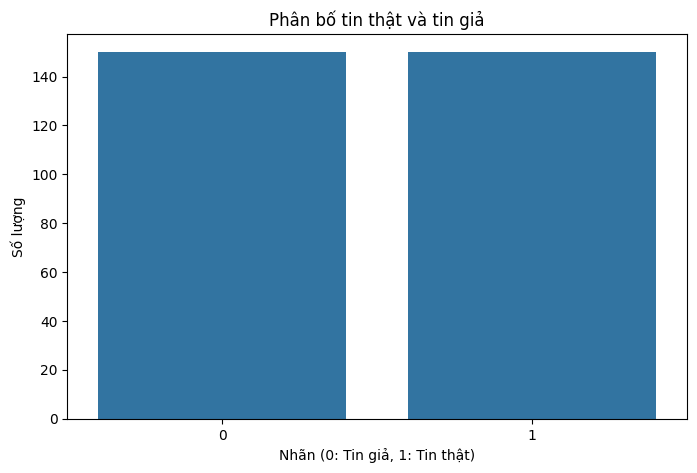

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="label")

plt.title("Phân bố tin thật và tin giả")
plt.xlabel("Nhãn (0: Tin giả, 1: Tin thật)")
plt.ylabel("Số lượng")

plt.show()

count    300.000000
mean     311.233333
std       42.563966
min      192.000000
25%      286.000000
50%      319.000000
75%      340.000000
max      389.000000
Name: text_length, dtype: float64


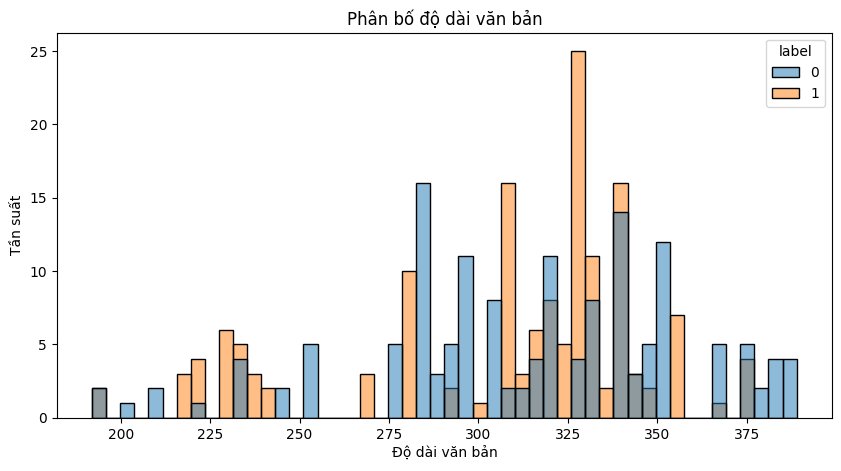

In [ ]:
df["text_length"] = df["text"].astype(str).apply(len)

print(df["text_length"].describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="text_length",
    hue="label",
    bins=50
)

plt.title("Phân bố độ dài văn bản")
plt.xlabel("Độ dài văn bản")
plt.ylabel("Tần suất")

plt.show()

In [ ]:
df.to_csv("fake_news_dataset.csv", index=False)

print("Đã lưu dữ liệu thành công!")

Đã lưu dữ liệu thành công!


In [ ]:
from google.colab import files

files.download("fake_news_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>